# Stage 1 重跑：GRU / Mamba / Transformer（依老師第 9、17 項）

| 項目 | 做法 |
|---|---|
| 資料 | `btc_max_ohlc_yfinance.csv`，2021-07-01 ～ 2026-05-10（與報告 Stage 1 相同），只用 Close |
| 共同測試日期 | 三個模型的視窗長度不同（20 / 30 天），一律從第 30 天開始建樣本 → **測試目標日期完全相同** |
| 切分 | 依目標日期：前 80% 訓練區（其中最後 10% 為驗證集）、後 20% 測試 |
| 資料洩漏 | MinMaxScaler **只用訓練集擬合**（原本 GRU、Transformer 都用全部資料） |
| 選 epoch | 用驗證 loss 最低的 epoch；測試集只在最後評估一次 |
| 基準 | Naive persistence（明日 = 今日），同一批測試日期 |
| 多 seed | 每個模型 seed 0–4 |
| 圖 | 重畫 Fig. 3：三個模型同一張圖、x 軸日期、y 軸「BTC-USD close (USD)」、統一圖例顏色 |

模型設定取自你們上傳的 GRU、Mamba notebook；Stage 1 Transformer 沒有 notebook，依報告 Table III 的描述實作。
**Mamba**：如果 `mamba_ssm` 裝不起來（Colab 常要編譯很久），會自動改用純 PyTorch 的 Mamba 區塊（同樣的 selective state-space 計算，只是比較慢；這裡資料量小，沒有影響）。

In [1]:
# ==========================================
# 設定
# ==========================================
import os, sys, json, math, time, random, platform, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from sklearn.preprocessing import MinMaxScaler
warnings.filterwarnings('ignore', message='enable_nested_tensor')

USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = Path('/content/drive/MyDrive/btc_transformer_results/stage1_rerun')
else:
    OUT_DIR = Path('btc_transformer_results/stage1_rerun')
PRED_DIR, LOSS_DIR, FIG_DIR = OUT_DIR / 'predictions', OUT_DIR / 'loss', OUT_DIR / 'figures'
for d in (PRED_DIR, LOSS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

DATA_PATH = 'btc_max_ohlc_yfinance.csv'
START_DATE, END_DATE = '2021-07-01', '2026-05-10'
SEEDS = [0, 1, 2, 3, 4]
TEST_FRAC, VAL_FRAC = 0.20, 0.10      # 測試 = 最後 20%；驗證 = 訓練區最後 10%
SELECT_BEST_VAL = True

MODELS = {   # 取自上傳的 notebook；Transformer 依報告 Table III
    'GRU':         dict(window=20, epochs=100, batch=32, lr=1e-3, units=100, dropout=0.2),
    'Mamba':       dict(window=30, epochs=50,  batch=32, lr=1e-4, d_model=64, d_state=16, d_conv=4, expand=2),
    'Transformer': dict(window=30, epochs=50,  batch=32, lr=1e-5, d_model=64, nhead=4, num_layers=2),
}
LMAX = max(c['window'] for c in MODELS.values())

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '| 結果資料夾：', OUT_DIR)

Mounted at /content/drive
device: cuda | 結果資料夾： /content/drive/MyDrive/btc_transformer_results/stage1_rerun


In [2]:
# ==========================================
# Mamba：優先用 mamba_ssm，裝不起來就用純 PyTorch 版本
# ==========================================
TRY_INSTALL_MAMBA_SSM = False     # True 會嘗試 pip 安裝（可能要編譯 20 分鐘以上）
if TRY_INSTALL_MAMBA_SSM:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'causal-conv1d', 'mamba-ssm', '--no-build-isolation'])
try:
    from mamba_ssm import Mamba as MambaSSM
    MAMBA_IMPL = 'mamba_ssm'
except Exception:
    MambaSSM = None
    MAMBA_IMPL = 'pure PyTorch (reference selective scan)'

class MambaBlockTorch(nn.Module):
    """與 mamba_ssm.Mamba 相同結構的純 PyTorch 版本（in_proj → causal conv → SiLU → selective scan → gate → out_proj）"""
    def __init__(self, d_model, d_state=16, d_conv=4, expand=2, dt_min=0.001, dt_max=0.1):
        super().__init__()
        self.d_inner = expand * d_model
        self.d_state = d_state
        self.dt_rank = math.ceil(d_model / 16)
        self.in_proj = nn.Linear(d_model, self.d_inner * 2, bias=False)
        self.conv1d = nn.Conv1d(self.d_inner, self.d_inner, kernel_size=d_conv, groups=self.d_inner, padding=d_conv - 1)
        self.x_proj = nn.Linear(self.d_inner, self.dt_rank + 2 * d_state, bias=False)
        self.dt_proj = nn.Linear(self.dt_rank, self.d_inner, bias=True)
        dt_init_std = self.dt_rank ** -0.5
        nn.init.uniform_(self.dt_proj.weight, -dt_init_std, dt_init_std)
        dt = torch.exp(torch.rand(self.d_inner) * (math.log(dt_max) - math.log(dt_min)) + math.log(dt_min)).clamp(min=1e-4)
        with torch.no_grad():
            self.dt_proj.bias.copy_(dt + torch.log(-torch.expm1(-dt)))
        A = torch.arange(1, d_state + 1, dtype=torch.float32).repeat(self.d_inner, 1)
        self.A_log = nn.Parameter(torch.log(A))
        self.D = nn.Parameter(torch.ones(self.d_inner))
        self.out_proj = nn.Linear(self.d_inner, d_model, bias=False)

    def forward(self, x):                      # x: (B, L, d_model)
        B, L, _ = x.shape
        xz = self.in_proj(x)
        x, z = xz.chunk(2, dim=-1)
        x = self.conv1d(x.transpose(1, 2))[..., :L].transpose(1, 2)
        x = F.silu(x)
        dbc = self.x_proj(x)
        dt, Bm, Cm = torch.split(dbc, [self.dt_rank, self.d_state, self.d_state], dim=-1)
        dt = F.softplus(self.dt_proj(dt))      # (B, L, d_inner)
        A = -torch.exp(self.A_log)             # (d_inner, d_state)
        dA = torch.exp(dt.unsqueeze(-1) * A)   # (B, L, d_inner, d_state)
        dBx = dt.unsqueeze(-1) * Bm.unsqueeze(2) * x.unsqueeze(-1)
        h = torch.zeros(B, self.d_inner, self.d_state, device=x.device)
        ys = []
        for t in range(L):
            h = dA[:, t] * h + dBx[:, t]
            ys.append((h * Cm[:, t].unsqueeze(1)).sum(-1))
        y = torch.stack(ys, dim=1) + x * self.D
        return self.out_proj(y * F.silu(z))

print('Mamba implementation:', MAMBA_IMPL)

Mamba implementation: pure PyTorch (reference selective scan)


In [3]:
# ==========================================
# 執行環境
# ==========================================
import sklearn, matplotlib
try:
    import keras, tensorflow as tf
    KERAS_V, TF_V = keras.__version__, tf.__version__
except Exception:
    KERAS_V = TF_V = None
ENV = {'recorded_at': pd.Timestamp.now(tz='Asia/Taipei').isoformat(timespec='seconds'),
       'python': sys.version.split()[0], 'torch': torch.__version__, 'torch_cuda_build': torch.version.cuda,
       'tensorflow': TF_V, 'keras': KERAS_V, 'numpy': np.__version__, 'pandas': pd.__version__,
       'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__,
       'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only',
       'mamba_impl': MAMBA_IMPL}
with open(OUT_DIR / 'environment_log.jsonl', 'a', encoding='utf-8') as f:
    f.write(json.dumps(ENV, ensure_ascii=False) + '\n')
for k, v in ENV.items(): print(f'{k:17s}: {v}')

recorded_at      : 2026-11-21T23:10:10+08:00
python           : 3.13.16
torch            : 2.14.1+cu130
torch_cuda_build : 13.0
tensorflow       : 2.21.0
keras            : 3.13.2
numpy            : 2.4.6
pandas           : 2.2.3
scikit-learn     : 1.6.1
matplotlib       : 3.10.0
gpu              : Tesla T4
mamba_impl       : pure PyTorch (reference selective scan)


## 資料準備
所有模型都預測同一批目標日期：從第 `LMAX` = 30 天開始建樣本，GRU（20 天視窗）只取每個目標日的前 20 天。

In [4]:
raw = pd.read_csv(DATA_PATH)
raw.columns = raw.columns.str.lower()
raw['date'] = pd.to_datetime(raw['date'].astype(str).str[:10])
raw = raw.sort_values('date')
raw = raw[(raw['date'] >= START_DATE) & (raw['date'] <= END_DATE)].reset_index(drop=True)
close = raw['close'].values.astype(float)
dates = raw['date'].values

n_samples = len(close) - LMAX
n_trainval = int(n_samples * (1 - TEST_FRAC))
n_train = int(n_trainval * (1 - VAL_FRAC))
n_val = n_trainval - n_train
n_test = n_samples - n_trainval
target_rows = np.arange(LMAX, len(close))
split = np.array(['train'] * n_train + ['val'] * n_val + ['test'] * n_test)
SPLITS = ['train', 'val', 'test']

# 只用訓練集擬合 scaler
train_last_row = target_rows[n_train - 1]
scaler = MinMaxScaler().fit(close[:train_last_row + 1].reshape(-1, 1))
scaled = scaler.transform(close.reshape(-1, 1)).astype(np.float32)[:, 0]

def make_xy(L):
    X = np.stack([scaled[r - L:r] for r in target_rows])[..., None]     # (樣本數, L, 1)
    return X, scaled[target_rows]

samples = pd.DataFrame({'target_date': dates[target_rows], 'split': split,
                        'actual': close[target_rows], 'naive': close[target_rows - 1]})

def calc_metrics(actual, pred, prev=None):
    a, p = np.asarray(actual, float), np.asarray(pred, float)
    e = p - a
    m = {'MSE': float(np.mean(e**2)), 'RMSE': float(np.sqrt(np.mean(e**2))),
         'MAE': float(np.mean(np.abs(e))), 'MAPE': float(np.mean(np.abs(e) / np.abs(a)) * 100)}
    m['DirAcc'] = float(np.mean(np.sign(a - prev) == np.sign(p - prev)) * 100) if prev is not None else np.nan
    return m

naive_metrics = {sp: calc_metrics(samples.loc[samples.split == sp, 'actual'], samples.loc[samples.split == sp, 'naive'])
                 for sp in SPLITS}
split_info = {'data': f"{raw['date'].iloc[0]:%Y-%m-%d} ~ {raw['date'].iloc[-1]:%Y-%m-%d}", 'rows': int(len(raw)), 'LMAX': LMAX}
for sp in SPLITS:
    g = samples[samples.split == sp]
    split_info[sp] = {'n': int(len(g)), 'first': f'{g.target_date.min():%Y-%m-%d}', 'last': f'{g.target_date.max():%Y-%m-%d}',
                      'close_min': float(g.actual.min()), 'close_max': float(g.actual.max())}
    print(f"{sp:5s} {len(g):5d} 天  {split_info[sp]['first']} ~ {split_info[sp]['last']}  Close {g.actual.min():,.0f} ~ {g.actual.max():,.0f}")
with open(OUT_DIR / 'split_info.json', 'w') as f:
    json.dump(split_info, f, indent=2)
print('\nNaive persistence (test):', {k: round(v, 2) for k, v in naive_metrics['test'].items() if k != 'DirAcc'})

train  1256 天  2021-07-31 ~ 2025-01-06  Close 15,787 ~ 106,141
val     140 天  2025-01-07 ~ 2025-05-26  Close 76,272 ~ 111,673
test    349 天  2025-05-27 ~ 2026-05-10  Close 62,702 ~ 124,753

Naive persistence (test): {'MSE': 3931653.69, 'RMSE': 1982.84, 'MAE': 1442.32, 'MAPE': 1.57}


## 模型
- **GRU**（Keras，與上傳的 notebook 相同）：GRU(100) → LayerNormalization → Dropout(0.2) → Dense(1, linear)；Adam 0.001、batch 32、100 epochs、20 天視窗
- **Mamba**（PyTorch，與上傳的 notebook 相同）：Linear(1→64) → Mamba(d_state 16, d_conv 4, expand 2) → 最後一步 → Linear(64→1)；Adam 0.0001、batch 32、50 epochs、30 天視窗
- **Transformer**（PyTorch，依報告 Table III）：Linear(1→64) → 正弦位置編碼 → 2 層 encoder（4 heads，PyTorch 預設 feed-forward 2048、dropout 0.1）→ 最後一步 → Linear(64→1)；Adam 0.00001、batch 32、50 epochs、30 天視窗

In [5]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

class TimeSeriesMamba(nn.Module):
    def __init__(self, d_model=64, d_state=16, d_conv=4, expand=2):
        super().__init__()
        self.input_linear = nn.Linear(1, d_model)
        self.mamba = (MambaSSM(d_model=d_model, d_state=d_state, d_conv=d_conv, expand=expand) if MambaSSM
                      else MambaBlockTorch(d_model, d_state, d_conv, expand))
        self.output_linear = nn.Linear(d_model, 1)
    def forward(self, x):                      # (B, L, 1)
        return self.output_linear(self.mamba(self.input_linear(x))[:, -1, :])

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))
    def forward(self, x):                      # (B, L, d)
        return x + self.pe[:, :x.size(1)]

class TimeSeriesTransformer(nn.Module):
    def __init__(self, d_model=64, nhead=4, num_layers=2):
        super().__init__()
        self.input_linear = nn.Linear(1, d_model)
        self.pos = PositionalEncoding(d_model)
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.decoder = nn.Linear(d_model, 1)
    def forward(self, x):
        return self.decoder(self.encoder(self.pos(self.input_linear(x)))[:, -1, :])

def run_torch(name, cfg, seed):
    set_seed(seed)
    X, y = make_xy(cfg['window'])
    Xt, yt = torch.tensor(X), torch.tensor(y).unsqueeze(-1)
    tr, va = slice(0, n_train), slice(n_train, n_trainval)
    model = (TimeSeriesMamba(cfg['d_model'], cfg['d_state'], cfg['d_conv'], cfg['expand']) if name == 'Mamba'
             else TimeSeriesTransformer(cfg['d_model'], cfg['nhead'], cfg['num_layers'])).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    crit = nn.MSELoss()
    g = torch.Generator().manual_seed(seed)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xt[tr], yt[tr]),
                                         batch_size=cfg['batch'], shuffle=True, generator=g)
    Xva, yva = Xt[va].to(device), yt[va].to(device)
    hist, best, best_ep, best_state = [], float('inf'), None, None
    for ep in range(1, cfg['epochs'] + 1):
        model.train(); tot, cnt = 0.0, 0
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            opt.zero_grad(); loss = crit(model(bx), by); loss.backward(); opt.step()
            tot += loss.item() * len(bx); cnt += len(bx)
        model.eval()
        with torch.no_grad():
            vl = crit(model(Xva), yva).item()
        hist.append((ep, tot / cnt, vl))
        if vl < best:
            best, best_ep = vl, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    if SELECT_BEST_VAL:
        model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred = torch.cat([model(Xt[i:i + 512].to(device)).cpu() for i in range(0, len(Xt), 512)]).numpy()
    return scaler.inverse_transform(pred)[:, 0], hist, best_ep

def run_gru(cfg, seed):
    import keras
    keras.utils.set_random_seed(seed)
    X, y = make_xy(cfg['window'])
    tr, va = slice(0, n_train), slice(n_train, n_trainval)
    model = keras.Sequential([keras.Input((cfg['window'], 1)), keras.layers.GRU(cfg['units']),
                              keras.layers.LayerNormalization(), keras.layers.Dropout(cfg['dropout']),
                              keras.layers.Dense(1), keras.layers.Activation('linear')])
    model.compile(optimizer=keras.optimizers.Adam(cfg['lr']), loss='mse')

    class BestVal(keras.callbacks.Callback):
        def __init__(self): super().__init__(); self.best, self.ep, self.w = float('inf'), None, None
        def on_epoch_end(self, epoch, logs=None):
            if logs['val_loss'] < self.best:
                self.best, self.ep, self.w = logs['val_loss'], epoch + 1, self.model.get_weights()
    cb = BestVal()
    h = model.fit(X[tr], y[tr], validation_data=(X[va], y[va]), epochs=cfg['epochs'],
                  batch_size=cfg['batch'], shuffle=True, verbose=0, callbacks=[cb])
    if SELECT_BEST_VAL:
        model.set_weights(cb.w)
    pred = model.predict(X, batch_size=512, verbose=0)
    hist = list(zip(range(1, cfg['epochs'] + 1), h.history['loss'], h.history['val_loss']))
    return scaler.inverse_transform(pred)[:, 0], hist, cb.ep

In [6]:
# ==========================================
# 儲存與批次執行（可中斷續跑）
# ==========================================
RUNS_CSV = OUT_DIR / 'runs_metrics.csv'

def completed():
    return set(zip(*pd.read_csv(RUNS_CSV)[['model', 'seed']].values.T)) if RUNS_CSV.exists() else set()

def record(name, seed, pred, hist, best_ep, sec):
    p = samples[['target_date', 'split', 'actual']].copy()
    p['predicted'] = pred; p['model'] = name; p['seed'] = seed
    p.to_csv(PRED_DIR / f'{name}__seed{seed}.csv', index=False)
    pd.DataFrame(hist, columns=['epoch', 'train_loss', 'val_loss']).to_csv(LOSS_DIR / f'{name}__seed{seed}.csv', index=False)
    row = {'model': name, 'seed': seed, 'window': MODELS[name]['window'], 'epochs': MODELS[name]['epochs'],
           'best_epoch': best_ep, 'train_time_s': round(sec, 1), 'gpu': ENV['gpu'],
           'impl': MAMBA_IMPL if name == 'Mamba' else ''}
    for sp in SPLITS:
        m = (p.split == sp).values
        for k, v in calc_metrics(p.loc[m, 'actual'], p.loc[m, 'predicted'], samples.loc[m, 'naive']).items():
            row[f'{sp}_{k}'] = v
    pd.DataFrame([row]).to_csv(RUNS_CSV, mode='a', header=not RUNS_CSV.exists(), index=False)
    return row

done = completed()
todo = [(n, s) for n in MODELS for s in SEEDS if (n, s) not in done]
print(f'待跑 {len(todo)} 次')
for name, seed in todo:
    t0 = time.time()
    pred, hist, best_ep = run_gru(MODELS[name], seed) if name == 'GRU' else run_torch(name, MODELS[name], seed)
    row = record(name, seed, pred, hist, best_ep, time.time() - t0)
    print(f"{name:12s} seed={seed}  best_epoch={best_ep}  test RMSE={row['test_RMSE']:,.0f}  MAPE={row['test_MAPE']:.2f}%  ({row['train_time_s']}s)")

待跑 15 次
GRU          seed=0  best_epoch=55  test RMSE=2,185  MAPE=1.74%  (49.2s)
GRU          seed=1  best_epoch=46  test RMSE=2,098  MAPE=1.66%  (41.6s)


GRU          seed=2  best_epoch=76  test RMSE=2,167  MAPE=1.72%  (41.2s)
GRU          seed=3  best_epoch=61  test RMSE=2,060  MAPE=1.64%  (41.8s)
GRU          seed=4  best_epoch=96  test RMSE=2,154  MAPE=1.73%  (41.3s)
Mamba        seed=0  best_epoch=48  test RMSE=2,070  MAPE=1.65%  (40.9s)
Mamba        seed=1  best_epoch=49  test RMSE=2,025  MAPE=1.62%  (33.4s)
Mamba        seed=2  best_epoch=48  test RMSE=2,039  MAPE=1.62%  (32.7s)
Mamba        seed=3  best_epoch=45  test RMSE=2,070  MAPE=1.66%  (32.8s)
Mamba        seed=4  best_epoch=49  test RMSE=2,061  MAPE=1.64%  (32.2s)
Transformer  seed=0  best_epoch=17  test RMSE=3,564  MAPE=2.89%  (13.9s)
Transformer  seed=1  best_epoch=32  test RMSE=3,458  MAPE=2.81%  (13.8s)
Transformer  seed=2  best_epoch=16  test RMSE=3,521  MAPE=2.85%  (13.8s)
Transformer  seed=3  best_epoch=34  test RMSE=3,350  MAPE=2.74%  (14.0s)
Transformer  seed=4  best_epoch=44  test RMSE=3,809  MAPE=3.18%  (14.1s)


## 結果表（報告第 9 項）
`stage1_table.csv`：三個模型（5 個 seed 平均 ± 標準差）與 Naive persistence，同一批測試日期。

In [7]:
runs = pd.read_csv(RUNS_CSV).drop_duplicates(['model', 'seed'], keep='last')
def pm(m, s, f): return f'{m:{f}} ± {s:{f}}' if pd.notna(s) else f'{m:{f}}'
nm = naive_metrics['test']
rows = [{'Model': 'Naive persistence', 'Window': '–', 'Epochs (selected, median)': '–', 'Seeds': '–',
         'Test RMSE (USD)': f"{nm['RMSE']:,.0f}", 'Test MAE (USD)': f"{nm['MAE']:,.0f}",
         'Test MAPE (%)': f"{nm['MAPE']:.2f}", 'Directional accuracy (%)': '–'}]
for name in MODELS:
    r = runs[runs.model == name]
    if r.empty: continue
    rows.append({'Model': name, 'Window': MODELS[name]['window'],
                 'Epochs (selected, median)': f"{MODELS[name]['epochs']} ({r.best_epoch.median():.0f})",
                 'Seeds': len(r),
                 'Test RMSE (USD)': pm(r.test_RMSE.mean(), r.test_RMSE.std(), ',.0f'),
                 'Test MAE (USD)': pm(r.test_MAE.mean(), r.test_MAE.std(), ',.0f'),
                 'Test MAPE (%)': pm(r.test_MAPE.mean(), r.test_MAPE.std(), '.2f'),
                 'Directional accuracy (%)': pm(r.test_DirAcc.mean(), r.test_DirAcc.std(), '.1f')})
stage1_table = pd.DataFrame(rows)
stage1_table.to_csv(OUT_DIR / 'stage1_table.csv', index=False)
print(f"測試期 {split_info['test']['first']} ~ {split_info['test']['last']}（{split_info['test']['n']} 天）")
display(stage1_table)

# 逐日預測（seed 平均）
test = samples[samples.split == 'test'][['target_date', 'actual', 'naive']].reset_index(drop=True)
for name in MODELS:
    seeds = sorted(runs.loc[runs.model == name, 'seed'])
    if not seeds: continue
    P = pd.concat([pd.read_csv(PRED_DIR / f'{name}__seed{s}.csv', parse_dates=['target_date']).assign(seed=s) for s in seeds])
    piv = P[P.split == 'test'].pivot(index='target_date', columns='seed', values='predicted').reindex(test.target_date)
    test[f'{name} mean'], test[f'{name} std'] = piv.mean(axis=1).values, piv.std(axis=1).values
test.to_csv(OUT_DIR / 'stage1_test_predictions_wide.csv', index=False)

測試期 2025-05-27 ~ 2026-05-10（349 天）


,Model,Window,"Epochs (selected, median)",Seeds,Test RMSE (USD),Test MAE (USD),Test MAPE (%),Directional accuracy (%)
0,Naive persistence,–,–,–,"1,983","1,442",1.57,–
1,GRU,20,100 (61),5,"2,133 ± 52","1,579 ± 49",1.70 ± 0.05,54.0 ± 1.4
2,Mamba,30,50 (48),5,"2,053 ± 20","1,507 ± 19",1.64 ± 0.02,50.3 ± 2.1
3,Transformer,30,50 (32),5,"3,540 ± 170","2,707 ± 145",2.90 ± 0.17,52.4 ± 2.4


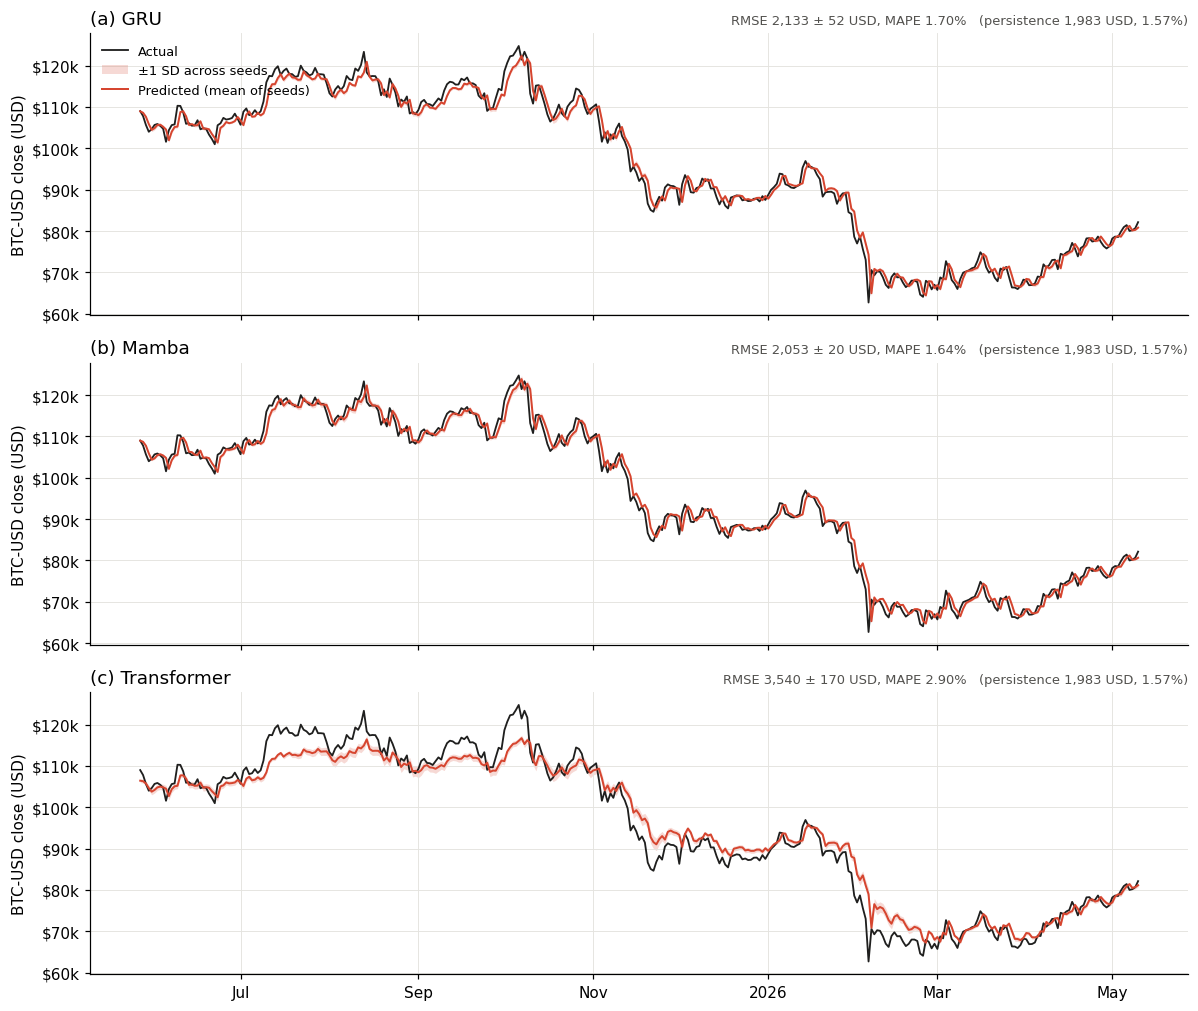

已存： /content/drive/MyDrive/btc_transformer_results/stage1_rerun/figures/fig3_stage1_test_period.png


In [8]:
# ==========================================
# 重畫 Fig. 3（老師第 17 項）：三個模型同一張圖、x 軸日期、統一標籤與顏色
# ==========================================
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e4e3df', 'grid.linewidth': 0.6, 'legend.frameon': False, 'legend.fontsize': 8.5})
COL_ACTUAL, COL_PRED = '#1f1f1e', '#d6452f'
usd_k = FuncFormatter(lambda v, _: f'${v/1000:,.0f}k')

names = [n for n in MODELS if f'{n} mean' in test]
fig, axes = plt.subplots(len(names), 1, figsize=(11, 3.1 * len(names)), sharex=True, sharey=True)
axes = np.atleast_1d(axes)
for ax, name, tag in zip(axes, names, 'abc'):
    r = runs[runs.model == name]
    m, s = test[f'{name} mean'], test[f'{name} std'].fillna(0)
    ax.plot(test.target_date, test.actual, color=COL_ACTUAL, lw=1.2, label='Actual')
    ax.fill_between(test.target_date, m - s, m + s, color=COL_PRED, alpha=0.2, lw=0, label='±1 SD across seeds')
    ax.plot(test.target_date, m, color=COL_PRED, lw=1.3, label='Predicted (mean of seeds)')
    ax.set_title(f'({tag}) {name}', loc='left')
    ax.set_title(f"RMSE {pm(r.test_RMSE.mean(), r.test_RMSE.std(), ',.0f')} USD, MAPE {r.test_MAPE.mean():.2f}%   "
                 f"(persistence {nm['RMSE']:,.0f} USD, {nm['MAPE']:.2f}%)", loc='right', fontsize=8.5, color='#52514e')
    ax.set_ylabel('BTC-USD close (USD)')
    ax.yaxis.set_major_formatter(usd_k)
loc = mdates.AutoDateLocator()
axes[-1].xaxis.set_major_locator(loc); axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
axes[0].legend(loc='upper left')
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig3_stage1_test_period.png', bbox_inches='tight')
plt.show()
print('已存：', FIG_DIR / 'fig3_stage1_test_period.png')